# Data Penjualan PT Graha Material Nusantara

## 0. Konfigurasi

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
AKAR = Path.cwd()
if not (AKAR / "data" / "raw").exists():
    AKAR = AKAR.parent
RAW = AKAR / "data" / "raw"
BERSIH = AKAR / "data" / "cleaned"
AWAL = pd.Timestamp("2019-01-01")
AKHIR = pd.Timestamp("2026-10-31")
SENTINEL = {"", "nan", "n/a", "-", "null", "none", "0000-00-00"}
BERKAS = ["pelanggan", "produk", "kategori", "wilayah", "tenaga_penjualan", "transaksi"]

BULAN = {
    "januari": 1, "februari": 2, "maret": 3, "april": 4, "mei": 5, "juni": 6,
    "juli": 7, "agustus": 8, "september": 9, "oktober": 10, "november": 11, "desember": 12,
}
FORMAT_TANGGAL = ("%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y", "%d-%b-%y", "%d %B %Y")
TERMIN = {
    "cod": "COD", "cash on delivery": "COD",
    "30": "30 Hari", "net 30": "30 Hari", "30 hari": "30 Hari",
    "45": "45 Hari", "net 45": "45 Hari", "45 hari": "45 Hari",
    "60": "60 Hari", "net 60": "60 Hari", "60 hari": "60 Hari",
}
SEGMEN = {"platinum": "Platinum", "gold": "Gold", "silver": "Silver", "bronze": "Bronze"}
KATEGORI = {
    "material dasar": "Material Dasar", "besi dan baja": "Besi dan Baja",
    "agregat": "Agregat", "material dinding": "Material Dinding",
    "atap dan rangka": "Atap dan Rangka", "finishing": "Finishing", "cat": "Cat",
    "keramik dan lantai": "Keramik dan Lantai", "instalasi": "Instalasi",
    "alat dan perlengkapan": "Alat dan Perlengkapan",
}
PROVINSI = {
    "jabar": "Jawa Barat", "jawa barat": "Jawa Barat",
    "dki jakarta": "DKI Jakarta", "jakarta": "DKI Jakarta",
    "banten": "Banten", "jateng": "Jawa Tengah", "jawa tengah": "Jawa Tengah",
    "jatim": "Jawa Timur", "jawa timur": "Jawa Timur",
    "sumut": "Sumatera Utara", "sumatera utara": "Sumatera Utara",
    "sumsel": "Sumatera Selatan", "sumatera selatan": "Sumatera Selatan",
    "sumbar": "Sumatera Barat", "sumatera barat": "Sumatera Barat",
    "riau": "Riau", "kaltim": "Kalimantan Timur", "kalimantan timur": "Kalimantan Timur",
    "kalsel": "Kalimantan Selatan", "kalimantan selatan": "Kalimantan Selatan",
    "sulsel": "Sulawesi Selatan", "sulawesi selatan": "Sulawesi Selatan",
    "sulut": "Sulawesi Utara", "sulawesi utara": "Sulawesi Utara",
}
KOTA = {
    "bdg": "Bandung", "kota bandung": "Bandung", "bandung": "Bandung",
    "bekasi": "Bekasi", "kota bekasi": "Bekasi", "bogor": "Bogor", "kota bogor": "Bogor",
    "depok": "Depok", "kota depok": "Depok", "cimahi": "Cimahi", "kota cimahi": "Cimahi",
    "jakarta selatan": "Jakarta Selatan", "jkt selatan": "Jakarta Selatan", "jaksel": "Jakarta Selatan",
    "jakarta timur": "Jakarta Timur", "jkt timur": "Jakarta Timur", "jaktim": "Jakarta Timur",
    "jakarta barat": "Jakarta Barat", "jkt barat": "Jakarta Barat", "jakbar": "Jakarta Barat",
    "tangerang": "Tangerang", "kota tangerang": "Tangerang", "tng": "Tangerang",
    "serang": "Serang", "kota serang": "Serang",
    "semarang": "Semarang", "kota semarang": "Semarang", "smg": "Semarang",
    "surakarta": "Surakarta", "solo": "Surakarta",
    "magelang": "Magelang", "kota magelang": "Magelang",
    "surabaya": "Surabaya", "kota surabaya": "Surabaya", "sby": "Surabaya",
    "malang": "Malang", "kota malang": "Malang",
    "sidoarjo": "Sidoarjo", "kabupaten sidoarjo": "Sidoarjo",
    "medan": "Medan", "kota medan": "Medan", "mdn": "Medan",
    "palembang": "Palembang", "kota palembang": "Palembang", "plm": "Palembang",
    "padang": "Padang", "kota padang": "Padang",
    "pekanbaru": "Pekanbaru", "kota pekanbaru": "Pekanbaru", "pku": "Pekanbaru",
    "balikpapan": "Balikpapan", "kota balikpapan": "Balikpapan", "bpp": "Balikpapan",
    "banjarmasin": "Banjarmasin", "kota banjarmasin": "Banjarmasin", "bjm": "Banjarmasin",
    "makassar": "Makassar", "kota makassar": "Makassar", "mks": "Makassar",
    "manado": "Manado", "kota manado": "Manado", "mdo": "Manado",
}
METODE = {
    "transfer bank": "Transfer Bank", "tunai": "Tunai", "virtual account": "Virtual Account",
    "cek giro": "Cek Giro", "qris": "QRIS", "": "Tidak Diketahui",
}


def baca(nama: str) -> pd.DataFrame:
    return pd.read_csv(RAW / f"{nama}.csv", dtype=str, keep_default_na=False)


def rapikan(seri: pd.Series) -> pd.Series:
    return seri.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()


def ganti_sentinel(seri: pd.Series) -> pd.Series:
    teks = rapikan(seri)
    return teks.mask(teks.str.lower().isin(SENTINEL), "")


def ke_angka(nilai) -> float:
    teks = str(nilai).strip()
    if teks.lower() in SENTINEL:
        return np.nan
    teks = teks.replace("Rp", "").replace("rp", "").replace(" ", "")
    if "," in teks and "." in teks:
        teks = teks.replace(".", "").replace(",", ".")
    elif teks.count(",") > 1:
        teks = teks.replace(",", "")
    elif "," in teks:
        kiri, kanan = teks.split(",")
        teks = f"{kiri}.{kanan}" if len(kanan) <= 2 else f"{kiri}{kanan}"
    elif teks.count(".") > 1:
        teks = teks.replace(".", "")
    try:
        return float(teks)
    except ValueError:
        return np.nan


def ke_tanggal(nilai) -> pd.Timestamp:
    teks = str(nilai).strip()
    if teks.lower() in SENTINEL:
        return pd.NaT
    pola = re.match(r"^(\d{1,2})\s+([A-Za-z]+)\s+(\d{4})$", teks)
    if pola and pola.group(2).lower() in BULAN:
        return pd.Timestamp(
            year=int(pola.group(3)),
            month=BULAN[pola.group(2).lower()],
            day=int(pola.group(1)),
        )
    for format_ in FORMAT_TANGGAL:
        try:
            return pd.Timestamp(pd.to_datetime(teks, format=format_))
        except (ValueError, TypeError):
            continue
    hasil = pd.to_datetime(teks, errors="coerce", dayfirst=True)
    return hasil if not pd.isna(hasil) else pd.NaT


def nomor_urut(nilai) -> str:
    teks = str(nilai).strip()
    huruf, _, angka = teks.partition("-")
    return f"{huruf}-{angka.zfill(4)}"


def profil_berkas(nama: str, df: pd.DataFrame) -> dict:
    kosong = df.apply(lambda s: s.astype(str).str.strip().str.lower().isin(SENTINEL).sum())
    return {
        "berkas": nama,
        "baris": len(df),
        "kolom": df.shape[1],
        "duplikat_baris": int(df.duplicated().sum()),
        "sel_kosong": int(kosong.sum()),
        "kolom_terdampak": int((kosong > 0).sum()),
    }

## 1. EDA

### 1.1 Profil Berkas

In [3]:
mentah = {nama: baca(nama) for nama in BERKAS}
tabel_mentah = pd.DataFrame([profil_berkas(nama, mentah[nama]) for nama in BERKAS])
tabel_mentah

,berkas,baris,kolom,duplikat_baris,sel_kosong,kolom_terdampak
0,pelanggan,102,10,2,4,1
1,produk,82,8,2,5,1
2,kategori,10,4,0,4,1
3,wilayah,25,6,1,0,0
4,tenaga_penjualan,15,8,0,10,1
5,transaksi,15700,15,300,2159,14


### 1.3 Kualitas Data

Transaksi adalah berkas paling tercemar: sekitar 14% sel berisi kosong atau kode pengganti dan ada 300 baris duplikat utuh.

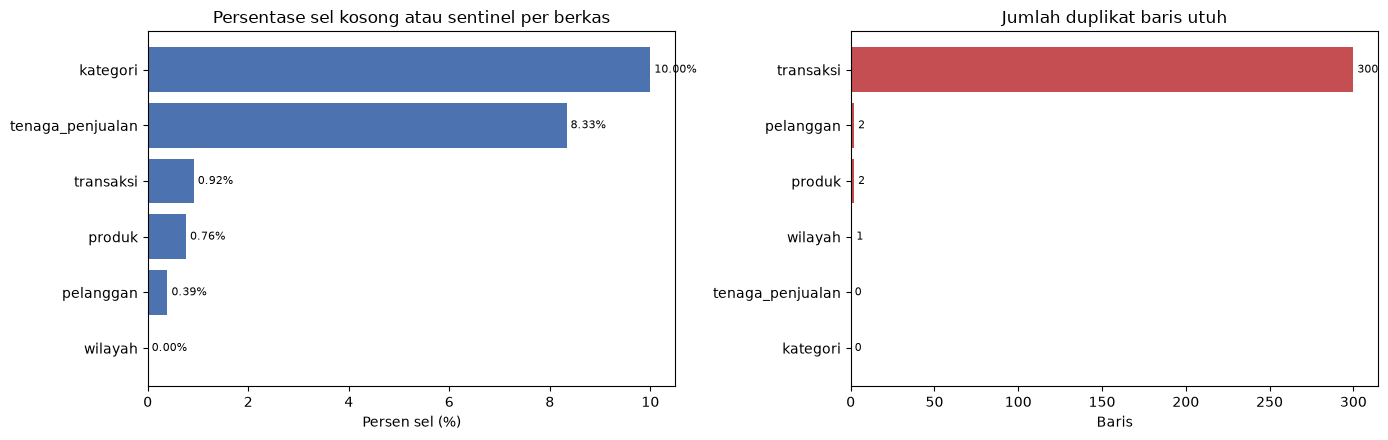

In [5]:
ringkas_kualitas = pd.DataFrame(
    [
        {
            "berkas": nama,
            "persen_kosong": mentah[nama]
            .apply(lambda s: s.astype(str).str.strip().str.lower().isin(SENTINEL).mean())
            .mean()
            * 100,
            "duplikat": int(mentah[nama].duplicated().sum()),
        }
        for nama in BERKAS
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

urut = ringkas_kualitas.sort_values("persen_kosong")
axes[0].barh(urut["berkas"], urut["persen_kosong"], color="#4c72b0")
for i, nilai in enumerate(urut["persen_kosong"]):
    axes[0].text(nilai, i, f" {nilai:.2f}%", va="center", fontsize=8)
axes[0].set_title("Persentase sel kosong atau sentinel per berkas")
axes[0].set_xlabel("Persen sel (%)")

urut = ringkas_kualitas.sort_values("duplikat")
axes[1].barh(urut["berkas"], urut["duplikat"], color="#c44e52")
for i, nilai in enumerate(urut["duplikat"]):
    axes[1].text(nilai, i, f" {int(nilai)}", va="center", fontsize=8)
axes[1].set_title("Jumlah duplikat baris utuh")
axes[1].set_xlabel("Baris")

plt.tight_layout()
plt.show()

### 1.4 Numerik Univariat

`jumlah` dan `harga_satuan` berekor panjang; boxplot memperlihatkan nilai 0, 9999, dan harga negatif yang tidak wajar.

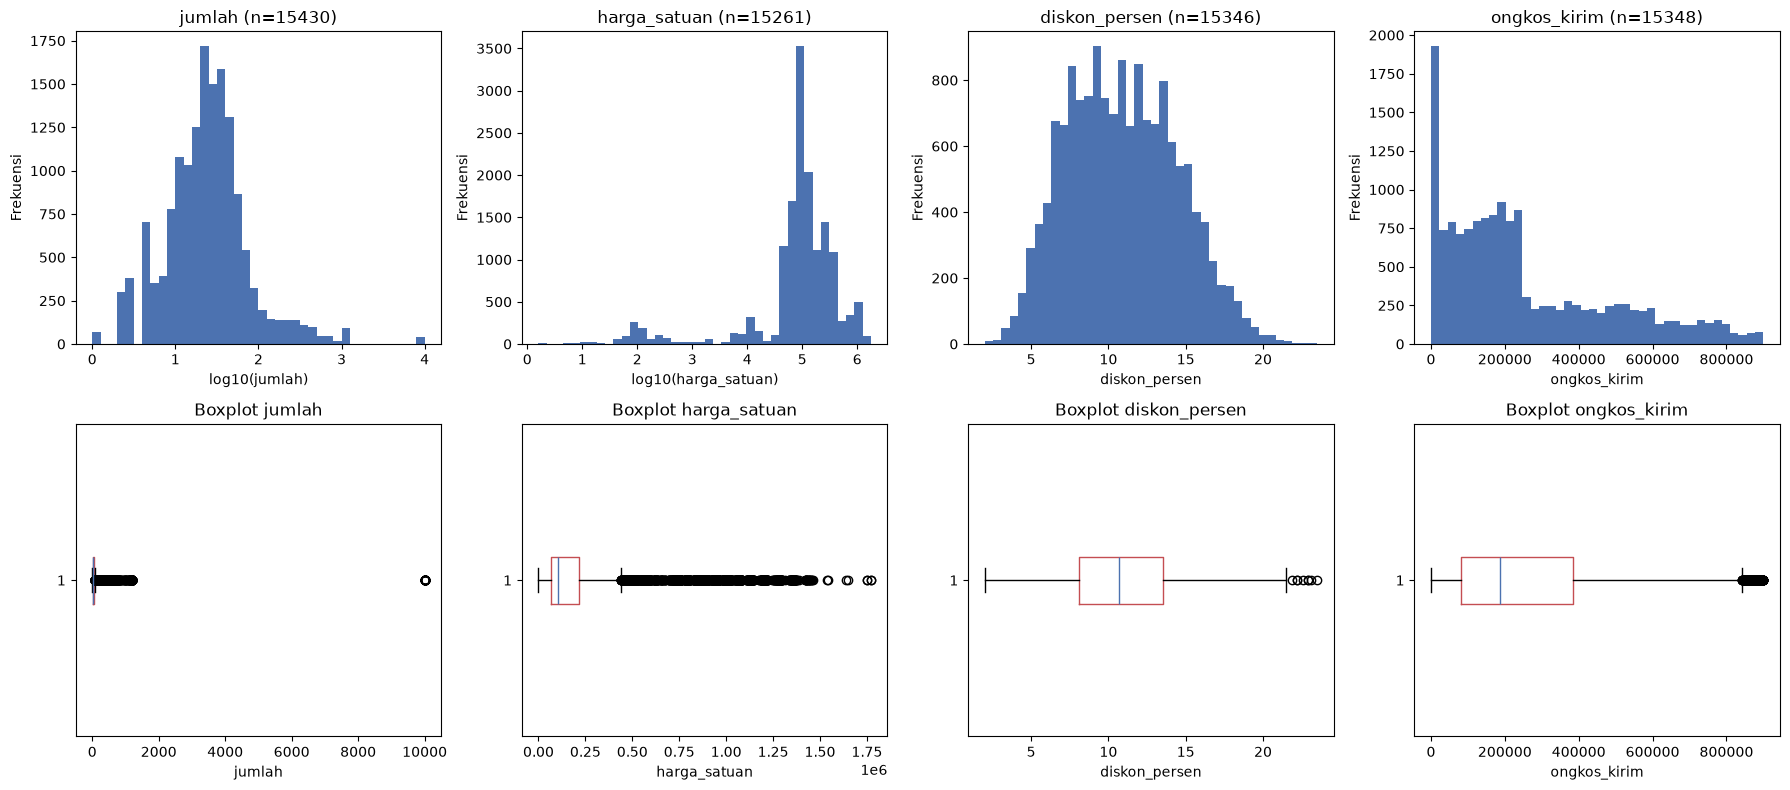

In [6]:
kolom_numerik = ["jumlah", "harga_satuan", "diskon_persen", "ongkos_kirim"]
numerik_mentah = pd.DataFrame(
    {kolom: mentah["transaksi"][kolom].map(ke_angka) for kolom in kolom_numerik}
)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for posisi, kolom in enumerate(kolom_numerik):
    nilai = numerik_mentah[kolom].dropna()
    ax_hist = axes[0, posisi]
    ax_box = axes[1, posisi]
    if kolom in {"jumlah", "harga_satuan"}:
        positif = nilai[nilai > 0]
        ax_hist.hist(np.log10(positif), bins=40, color="#4c72b0")
        ax_hist.set_xlabel(f"log10({kolom})")
    else:
        ax_hist.hist(nilai, bins=40, color="#4c72b0")
        ax_hist.set_xlabel(kolom)
    ax_hist.set_title(f"{kolom} (n={len(nilai)})")
    ax_hist.set_ylabel("Frekuensi")
    ax_box.boxplot(nilai, orientation="horizontal", boxprops=dict(color="#c44e52"), medianprops=dict(color="#4c72b0"))
    ax_box.set_title(f"Boxplot {kolom}")
    ax_box.set_xlabel(kolom)

plt.tight_layout()
plt.show()

### 1.5 Numerik Multivariat

Korelasi Spearman masih lemah pada data mentah, tanda banyak nilai tidak valid dan outlier yang menutupi hubungan sebenarnya.

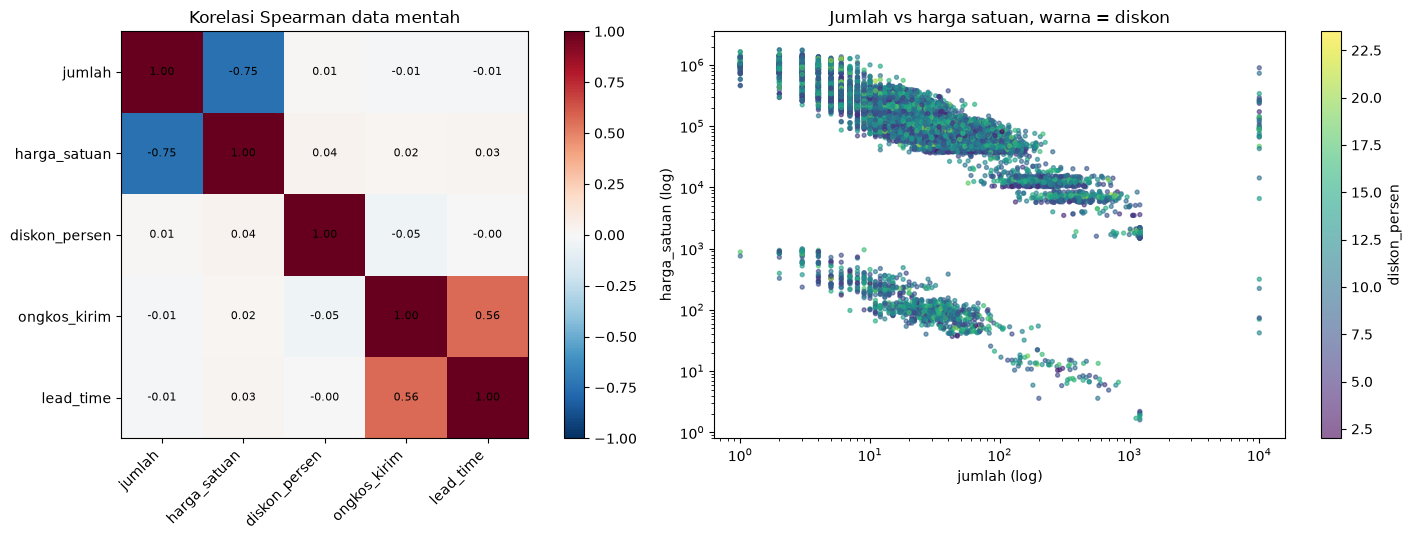

In [7]:
numerik_mentah["lead_time"] = (
    mentah["transaksi"]["tanggal_kirim"].map(ke_tanggal)
    - mentah["transaksi"]["tanggal_transaksi"].map(ke_tanggal)
).dt.days

korelasi = numerik_mentah.corr(method="spearman", numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

gambar = axes[0].imshow(korelasi, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(korelasi.columns)))
axes[0].set_xticklabels(korelasi.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(korelasi.columns)))
axes[0].set_yticklabels(korelasi.columns)
for i in range(len(korelasi)):
    for j in range(len(korelasi)):
        axes[0].text(j, i, f"{korelasi.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[0].set_title("Korelasi Spearman data mentah")
fig.colorbar(gambar, ax=axes[0], fraction=0.046)

scatter_data = numerik_mentah[
    (numerik_mentah["jumlah"] > 0) & (numerik_mentah["harga_satuan"] > 0)
]
sebaran = axes[1].scatter(
    scatter_data["jumlah"],
    scatter_data["harga_satuan"],
    c=scatter_data["diskon_persen"],
    cmap="viridis",
    s=8,
    alpha=0.6,
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("jumlah (log)")
axes[1].set_ylabel("harga_satuan (log)")
axes[1].set_title("Jumlah vs harga satuan, warna = diskon")
fig.colorbar(sebaran, ax=axes[1], label="diskon_persen")

plt.tight_layout()
plt.show()

### 1.6 Kategorikal Multivariat

Varian kapitalisasi memecah kategori yang seharusnya sama, terlihat dari label yang berulang pada crosstab.

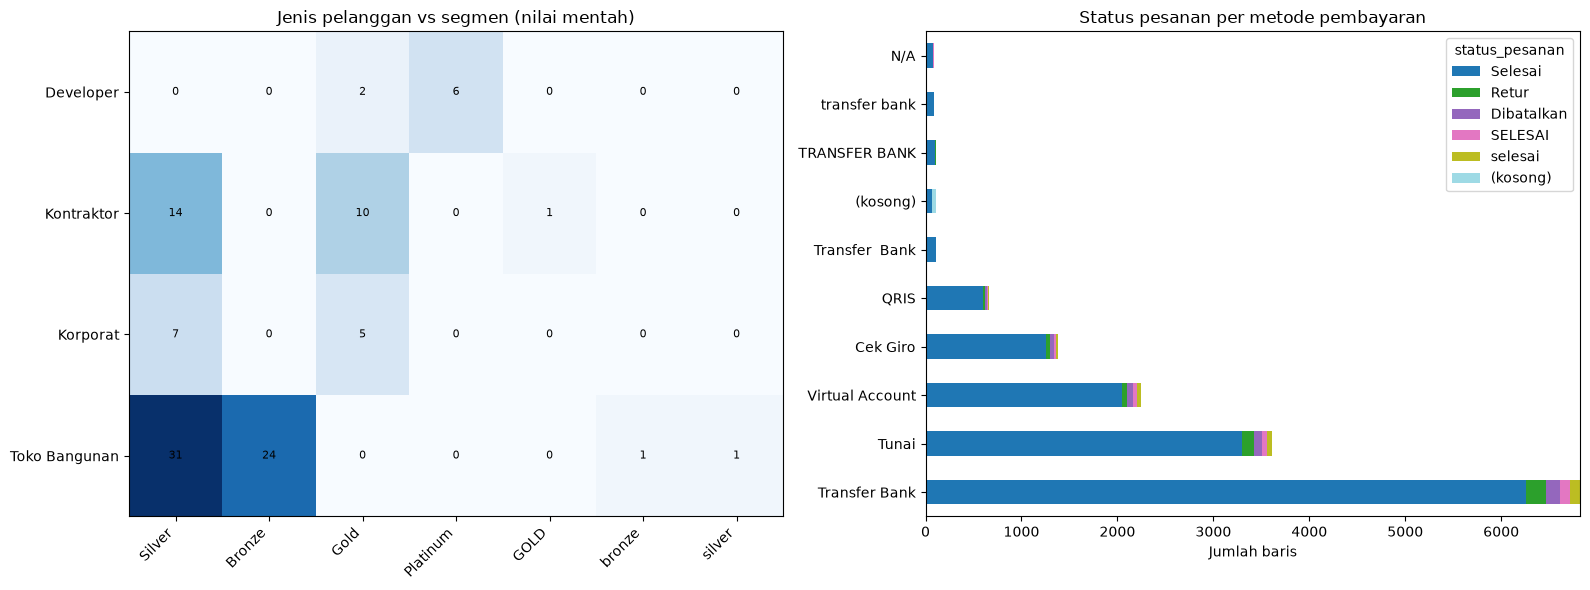

In [8]:
pelanggan_mentah = mentah["pelanggan"]
tabel_jenis = pd.crosstab(
    pelanggan_mentah["jenis_pelanggan"].str.strip(),
    pelanggan_mentah["segmen"].str.strip(),
)
tabel_jenis = tabel_jenis[tabel_jenis.sum().sort_values(ascending=False).index[:8]]

transaksi_mentah = mentah["transaksi"]
tabel_status = pd.crosstab(
    transaksi_mentah["metode_pembayaran"].str.strip().replace("", "(kosong)"),
    transaksi_mentah["status_pesanan"].str.strip().replace("", "(kosong)"),
)
tabel_status = tabel_status.loc[
    tabel_status.sum(axis=1).sort_values(ascending=False).index[:10],
    tabel_status.sum().sort_values(ascending=False).index[:6],
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(tabel_jenis, cmap="Blues", aspect="auto")
axes[0].set_xticks(range(len(tabel_jenis.columns)))
axes[0].set_xticklabels(tabel_jenis.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(tabel_jenis.index)))
axes[0].set_yticklabels(tabel_jenis.index)
for i in range(tabel_jenis.shape[0]):
    for j in range(tabel_jenis.shape[1]):
        axes[0].text(j, i, tabel_jenis.iat[i, j], ha="center", va="center", fontsize=8)
axes[0].set_title("Jenis pelanggan vs segmen (nilai mentah)")

tabel_status.plot(kind="barh", stacked=True, ax=axes[1], colormap="tab20")
axes[1].set_title("Status pesanan per metode pembayaran")
axes[1].set_xlabel("Jumlah baris")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 1.7 Pola Waktu

Rentang mencakup 94 bulan. Jumlah baris memuncak menjelang Lebaran dan Desember, sedangkan 2026 lebih rendah dari 2023-2025.

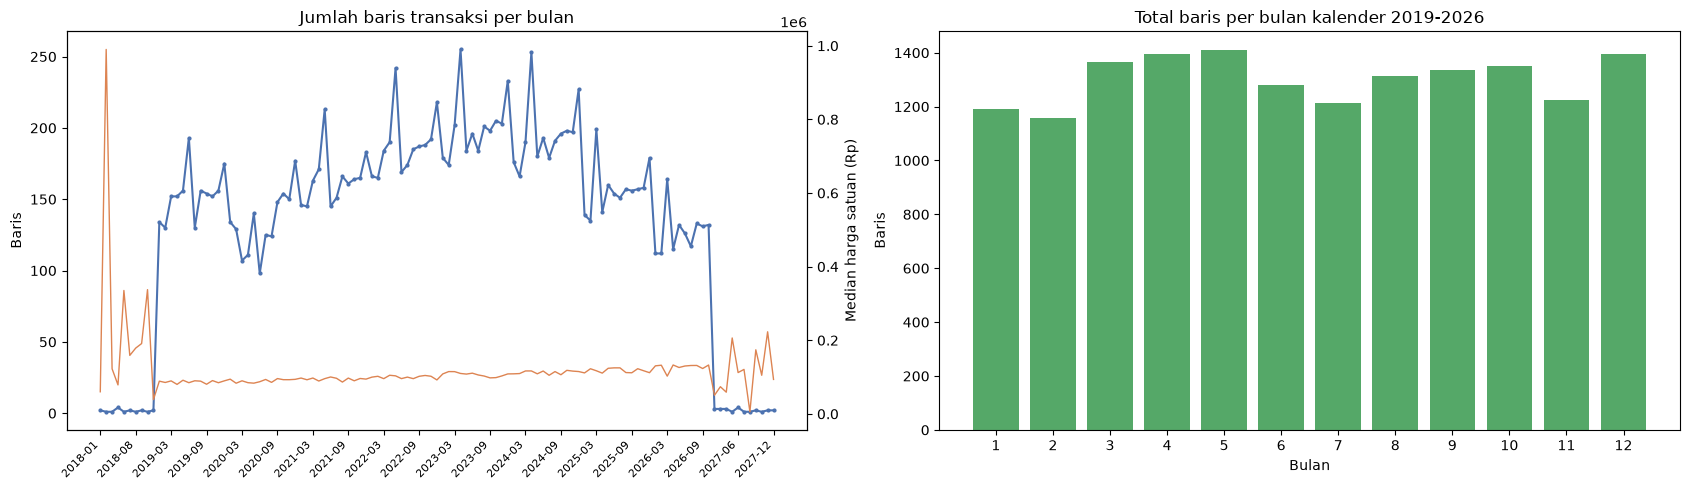

In [9]:
tanggal_mentah = mentah["transaksi"]["tanggal_transaksi"].map(ke_tanggal)
harga_mentah = mentah["transaksi"]["harga_satuan"].map(ke_angka)
waktu = pd.DataFrame({"tanggal": tanggal_mentah, "harga": harga_mentah}).dropna(subset=["tanggal"])
waktu["bulan"] = waktu["tanggal"].dt.to_period("M")
per_bulan = waktu.groupby("bulan").agg(
    baris=("harga", "size"), median_harga=("harga", "median")
)
label_bulan = per_bulan.index.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].plot(label_bulan, per_bulan["baris"], color="#4c72b0", marker="o", markersize=2)
axes[0].set_xticks(range(0, len(label_bulan), 6))
axes[0].set_xticklabels(label_bulan[::6], rotation=45, ha="right", fontsize=8)
axes[0].set_title("Jumlah baris transaksi per bulan")
axes[0].set_ylabel("Baris")
pasangan = axes[0].twinx()
pasangan.plot(label_bulan, per_bulan["median_harga"], color="#dd8452", linewidth=1)
pasangan.set_ylabel("Median harga satuan (Rp)")

musiman = waktu.assign(bulan_kalender=waktu["tanggal"].dt.month).groupby("bulan_kalender").size()
axes[1].bar(musiman.index, musiman.values, color="#55a868")
axes[1].set_xticks(range(1, 13))
axes[1].set_title("Total baris per bulan kalender 2019-2026")
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Baris")

plt.tight_layout()
plt.show()

### 1.8 Recency Pelanggan

Sebagian pelanggan sudah lama tidak bertransaksi. Ekor di atas 180 hari inilah yang menjadi dasar definisi churn.

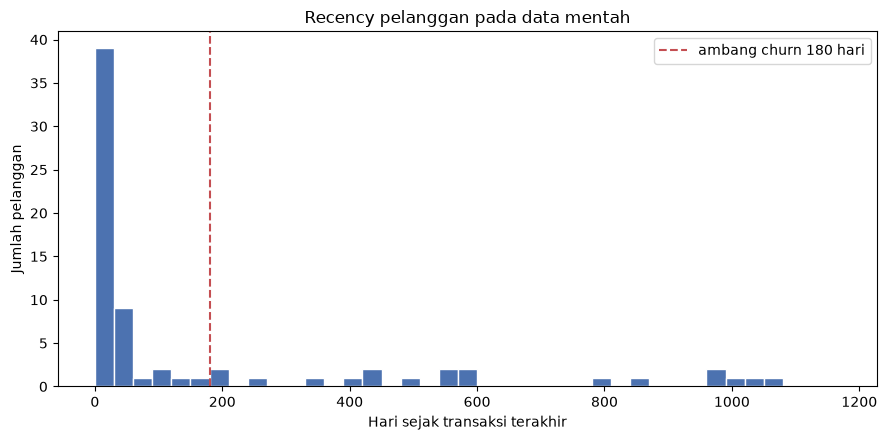

In [10]:
id_sah = set(mentah["pelanggan"]["id_pelanggan"].str.strip())
transaksi_mentah = mentah["transaksi"].assign(
    tanggal=mentah["transaksi"]["tanggal_transaksi"].map(ke_tanggal),
    id_bersih=mentah["transaksi"]["id_pelanggan"].map(nomor_urut),
)
transaksi_sah = transaksi_mentah[transaksi_mentah["id_bersih"].isin(id_sah)].dropna(subset=["tanggal"])
terakhir = transaksi_sah.groupby("id_bersih")["tanggal"].max()
recency = (AKHIR - terakhir).dt.days

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(recency, bins=np.arange(0, 1200, 30), color="#4c72b0", edgecolor="white")
ax.axvline(180, color="#c44e52", linestyle="--", label="ambang churn 180 hari")
ax.set_xlabel("Hari sejak transaksi terakhir")
ax.set_ylabel("Jumlah pelanggan")
ax.set_title("Recency pelanggan pada data mentah")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Masalah Data dan Aturan Cleaning

Angka pada tabel berasal dari audit seed 42. Beberapa baris terkena lebih dari satu aturan, sedangkan total baris transaksi yang dibuang adalah 280.

| Berkas | Kolom | Masalah | Baris |
|---|---|---|---|
| transaksi | seluruh kolom | duplikat baris utuh | 300 |
| transaksi | nomor_pesanan, id_produk | duplikat kunci pesanan | 120 |
| transaksi | tanggal_transaksi | kosong atau 0000-00-00 | 70 |
| transaksi | tanggal_transaksi | di luar 1 Jan 2019 sampai 31 Okt 2026 | 40 |
| transaksi | id_pelanggan | nol depan hilang atau id asing | 90 |
| transaksi | id_produk | nol depan hilang atau id asing | 80 |
| transaksi | jumlah | 0 atau 9999 | 80 |
| transaksi | harga_satuan | kosong, N/A, -, NULL | 439 |
| transaksi | jumlah | kosong, N/A, -, NULL | 270 |
| transaksi | diskon_persen | kosong, N/A, -, NULL | 354 |
| transaksi | ongkos_kirim | kosong, N/A, -, NULL | 352 |
| transaksi | harga_satuan, ongkos_kirim | angka berformat Rp atau koma | sekitar 2.100 per kolom |
| transaksi | status, metode, termin | kapitalisasi dan spasi ganda | sekitar 2.600 |
| pelanggan | id_wilayah | berisi nama kota, bukan kode | 10 |
| pelanggan | termin_pembayaran | tidak baku | 8 |
| pelanggan | limit_kredit | angka berformat teks | 10 |
| pelanggan | kanal_akuisisi | kosong | 4 |
| pelanggan | segmen | kapitalisasi dan spasi | 6 |
| pelanggan | seluruh kolom | duplikat baris | 2 |
| produk | harga_modal | angka berformat teks | 10 |
| produk | berat_kg | kosong | 5 |
| produk | status_aktif | kapitalisasi | 12 |
| produk | seluruh kolom | duplikat baris | 2 |
| wilayah | provinsi | alias dan kapitalisasi | 9 |
| wilayah | seluruh kolom | duplikat baris | 1 |
| kategori | nama_kategori | kapitalisasi dan spasi | 5 |
| tenaga_penjualan | tanggal_keluar | kode 0000-00-00 | 8 |

### 2.1 Aturan Cleaning

| Berkas | Masalah | Aturan |
|---|---|---|
| wilayah | duplikat, alias provinsi, spasi berlebih | trim, pemetaan provinsi baku, hapus duplikat id_wilayah |
| kategori | kapitalisasi dan spasi tidak konsisten | trim, pemetaan nama kategori baku |
| produk | duplikat, harga teks, berat kosong, status tidak baku | parse angka, median berat per kategori, standarisasi status |
| tenaga_penjualan | kode tanggal 0000-00-00, nama spasi ganda | sentinel menjadi kosong, trim, sinkron status dan tanggal keluar |
| pelanggan | duplikat, id_wilayah berupa kota, termin tidak baku, limit teks | pemetaan kota ke kode wilayah, pemetaan termin, parse angka, hapus duplikat |
| transaksi | tanggal campur, uang teks, duplikat, id tanpa nol, outlier, FK asing | parser tanggal berlapis, parse angka, zero-pad id, filter validitas, dedup, imputasi median per produk-tahun |

## 3. Cleaning Dimensi

### 3.1 Wilayah

In [11]:
wilayah = mentah["wilayah"].copy()
wilayah["provinsi"] = rapikan(wilayah["provinsi"]).str.lower().map(PROVINSI)
wilayah["kota"] = rapikan(wilayah["kota"]).str.title()
wilayah["zona_kirim"] = rapikan(wilayah["zona_kirim"])
wilayah["sla_kirim_hari"] = pd.to_numeric(rapikan(wilayah["sla_kirim_hari"]), errors="coerce").astype("Int64")
wilayah = wilayah.drop_duplicates(subset="id_wilayah", keep="first").reset_index(drop=True)
wilayah["id_wilayah"] = wilayah["id_wilayah"].str.strip()

peta_kota = {kota.lower(): kode for kota, kode in zip(wilayah["kota"], wilayah["id_wilayah"])}
peta_kota.update({alias: peta_kota[kota.lower()] for alias, kota in KOTA.items() if kota.lower() in peta_kota})

print(len(mentah["wilayah"]), "menjadi", len(wilayah), "baris")
wilayah.head()

25 menjadi 24 baris


,id_wilayah,provinsi,kota,region,zona_kirim,sla_kirim_hari
0,WIL-01,Jawa Barat,Bandung,Jawa,Zona 1,3
1,WIL-02,Jawa Barat,Bekasi,Jawa,Zona 1,2
2,WIL-03,Jawa Barat,Bogor,Jawa,Zona 1,3
3,WIL-04,Jawa Barat,Depok,Jawa,Zona 1,2
4,WIL-05,Jawa Barat,Cimahi,Jawa,Zona 1,3


### 3.2 Kategori

In [12]:
kategori = mentah["kategori"].copy()
kategori["nama_kategori"] = rapikan(kategori["nama_kategori"]).str.lower().map(KATEGORI)
kategori["deskripsi"] = rapikan(kategori["deskripsi"])
kategori["id_kategori_induk"] = kategori["id_kategori_induk"].fillna("").str.strip()
kategori["id_kategori"] = kategori["id_kategori"].str.strip()

print(len(mentah["kategori"]), "menjadi", len(kategori), "baris")
kategori.head()

10 menjadi 10 baris


,id_kategori,nama_kategori,id_kategori_induk,deskripsi
0,KAT-01,Material Dasar,,Kategori material dasar untuk kebutuhan proyek...
1,KAT-02,Besi dan Baja,KAT-01,Kategori besi dan baja untuk kebutuhan proyek ...
2,KAT-03,Agregat,KAT-01,Kategori agregat untuk kebutuhan proyek dan re...
3,KAT-04,Material Dinding,KAT-01,Kategori material dinding untuk kebutuhan proy...
4,KAT-05,Atap dan Rangka,KAT-01,Kategori atap dan rangka untuk kebutuhan proye...


### 3.3 Produk

In [13]:
produk = mentah["produk"].copy()
produk["nama_produk"] = rapikan(produk["nama_produk"])
produk["satuan"] = rapikan(produk["satuan"]).str.lower()
produk["harga_modal"] = produk["harga_modal"].map(ke_angka)
produk["harga_jual_acuan"] = produk["harga_jual_acuan"].map(ke_angka)
produk["berat_kg"] = produk["berat_kg"].map(ke_angka)
produk["id_kategori"] = produk["id_kategori"].str.strip()
produk["id_produk"] = produk["id_produk"].str.strip()
produk = produk.drop_duplicates(subset="id_produk", keep="first").reset_index(drop=True)
produk["berat_kg"] = produk["berat_kg"].fillna(produk.groupby("id_kategori")["berat_kg"].transform("median"))
produk["status_aktif"] = rapikan(produk["status_aktif"]).str.lower().map({"aktif": "Aktif", "nonaktif": "Nonaktif"})

print(len(mentah["produk"]), "menjadi", len(produk), "baris")
produk.head()

82 menjadi 80 baris


,id_produk,nama_produk,id_kategori,satuan,harga_modal,harga_jual_acuan,berat_kg,status_aktif
0,PRD-0001,Besi Beton Polos 8mm,KAT-02,batang,62000.0,69400.0,34.645,Aktif
1,PRD-0002,Besi Beton Polos 10mm,KAT-02,batang,95000.0,106400.0,26.610,Aktif
2,PRD-0003,Besi Beton Ulir 12mm,KAT-02,batang,138000.0,154600.0,34.645,Aktif
3,PRD-0004,Besi Beton Ulir 16mm,KAT-02,batang,245000.0,274400.0,41.990,Aktif
4,PRD-0005,Wiremesh M6,KAT-02,lembar,385000.0,427400.0,6.100,Aktif


### 3.4 Tenaga Penjualan

In [14]:
sales = mentah["tenaga_penjualan"].copy()
sales["nama_sales"] = rapikan(sales["nama_sales"])
sales["cabang"] = rapikan(sales["cabang"])
sales["region"] = rapikan(sales["region"])
sales["id_sales"] = sales["id_sales"].str.strip()
sales["tanggal_masuk"] = sales["tanggal_masuk"].map(ke_tanggal)
sales["tanggal_keluar"] = sales["tanggal_keluar"].map(ke_tanggal)
sales["status"] = rapikan(sales["status"]).str.lower().map({"aktif": "Aktif", "resign": "Resign"})
sales["target_bulanan"] = pd.to_numeric(rapikan(sales["target_bulanan"]), errors="coerce").astype("Int64")

print(sales["status"].value_counts().to_string())
sales.head()

status
Aktif     10
Resign     5


,id_sales,nama_sales,cabang,region,tanggal_masuk,tanggal_keluar,target_bulanan,status
0,SL-01,Agus Prasetyo,Cabang Bandung,Jawa,2019-06-16,NaT,48000000,Aktif
1,SL-02,Budi Santoso,Cabang Bandung,Jawa,2018-01-04,2026-05-31,39000000,Resign
2,SL-03,Citra Lestari,Cabang Bandung,Jawa,2018-01-12,NaT,53000000,Aktif
3,SL-04,Dedi Kurniawan,Cabang Bandung,Jawa,2017-10-17,2025-03-31,30000000,Resign
4,SL-05,Eka Wulandari,Cabang Bandung,Jawa,2017-10-28,NaT,25000000,Aktif


### 3.5 Pelanggan

In [15]:
pelanggan = mentah["pelanggan"].copy()
pelanggan["nama_pelanggan"] = rapikan(pelanggan["nama_pelanggan"])
pelanggan["jenis_pelanggan"] = rapikan(pelanggan["jenis_pelanggan"])
pelanggan["segmen"] = rapikan(pelanggan["segmen"]).str.lower().map(SEGMEN)
pelanggan["kanal_akuisisi"] = rapikan(pelanggan["kanal_akuisisi"]).replace("", "Tidak Diketahui")
pelanggan["termin_pembayaran"] = rapikan(pelanggan["termin_pembayaran"]).str.lower().map(TERMIN)
pelanggan["limit_kredit"] = pelanggan["limit_kredit"].map(ke_angka)
pelanggan["tanggal_registrasi"] = pelanggan["tanggal_registrasi"].map(ke_tanggal)
pelanggan["id_pelanggan"] = pelanggan["id_pelanggan"].str.strip()
pelanggan["id_sales"] = pelanggan["id_sales"].str.strip()


def peta_wilayah(nilai) -> str:
    teks = re.sub(r"\s+", " ", str(nilai)).strip()
    if teks.startswith("WIL-"):
        return teks
    return peta_kota.get(teks.lower())


pelanggan["id_wilayah"] = pelanggan["id_wilayah"].map(peta_wilayah)
pelanggan = pelanggan.drop_duplicates(subset="id_pelanggan", keep="first").reset_index(drop=True)

print(len(mentah["pelanggan"]), "menjadi", len(pelanggan), "baris")
print("id_wilayah tidak terpetakan:", pelanggan["id_wilayah"].isna().sum())
pelanggan.head()

102 menjadi 100 baris
id_wilayah tidak terpetakan: 0


,id_pelanggan,nama_pelanggan,jenis_pelanggan,segmen,id_wilayah,id_sales,tanggal_registrasi,kanal_akuisisi,termin_pembayaran,limit_kredit
0,CUST-0001,Toko Global Bangunan,Kontraktor,Gold,WIL-21,SL-13,2017-11-17,Kunjungan Sales,COD,180000000.0
1,CUST-0002,CV Rekatama Persada,Toko Bangunan,Silver,WIL-22,SL-13,2022-07-06,Pameran,COD,315000000.0
2,CUST-0003,Toko Mulia Niaga,Toko Bangunan,Bronze,WIL-07,SL-01,2020-04-16,Kunjungan Sales,COD,115000000.0
3,CUST-0004,Toko Anugerah Mandiri,Toko Bangunan,Silver,WIL-23,SL-15,2017-08-25,Referral,COD,170000000.0
4,CUST-0005,PT Griya Asri,Toko Bangunan,Silver,WIL-21,SL-13,2017-06-07,Website,30 Hari,160000000.0


## 4. Cleaning Transaksi

### 4.1 Konversi Tipe dan Validasi Baris

In [16]:
transaksi = mentah["transaksi"].copy()
transaksi["tanggal_transaksi"] = transaksi["tanggal_transaksi"].map(ke_tanggal)
transaksi["tanggal_kirim"] = transaksi["tanggal_kirim"].map(ke_tanggal)
transaksi["id_pelanggan"] = transaksi["id_pelanggan"].map(nomor_urut)
transaksi["id_produk"] = transaksi["id_produk"].map(nomor_urut)
for kolom in ["id_transaksi", "nomor_pesanan", "id_sales"]:
    transaksi[kolom] = transaksi[kolom].str.strip()

for kolom in ["jumlah", "harga_satuan", "diskon_persen", "ongkos_kirim"]:
    transaksi[kolom] = transaksi[kolom].map(ke_angka)

for kolom in ["metode_pembayaran", "termin_pembayaran", "status_pesanan", "status_pembayaran"]:
    transaksi[kolom] = ganti_sentinel(transaksi[kolom])

transaksi["status_pesanan"] = transaksi["status_pesanan"].str.lower().map(
    {"selesai": "Selesai", "retur": "Retur", "dibatalkan": "Dibatalkan"}
)
transaksi["metode_pembayaran"] = transaksi["metode_pembayaran"].str.lower().map(METODE)
transaksi["termin_pembayaran"] = transaksi["termin_pembayaran"].str.lower().map(TERMIN)
transaksi["status_pembayaran"] = transaksi["status_pembayaran"].str.lower().str.title()

alasan = {
    "tanggal tidak valid": transaksi["tanggal_transaksi"].isna(),
    "tanggal di luar periode": (transaksi["tanggal_transaksi"] < AWAL) | (transaksi["tanggal_transaksi"] > AKHIR),
    "pelanggan tidak dikenal": ~transaksi["id_pelanggan"].isin(pelanggan["id_pelanggan"]),
    "produk tidak dikenal": ~transaksi["id_produk"].isin(produk["id_produk"]),
    "jumlah tidak wajar": (transaksi["jumlah"] <= 0) | (transaksi["jumlah"] > 1500),
}
saringan = pd.DataFrame(alasan)
saringan["total"] = saringan.any(axis=1)

print(len(transaksi), "baris mentah")
print(saringan.sum().to_string())
transaksi = transaksi.loc[~saringan["total"]].reset_index(drop=True)
print(len(transaksi), "baris setelah validasi")

15700 baris mentah
tanggal tidak valid         70
tanggal di luar periode     40
pelanggan tidak dikenal     90
produk tidak dikenal        80
jumlah tidak wajar          80
total                      280
15420 baris setelah validasi


### 4.2 Duplikasi

In [17]:
sebelum = len(transaksi)
transaksi = transaksi.drop_duplicates().reset_index(drop=True)
setelah_duplikat = len(transaksi)
transaksi = transaksi.sort_values(["tanggal_transaksi", "id_transaksi"]).reset_index(drop=True)
transaksi = transaksi.drop_duplicates(subset=["nomor_pesanan", "id_produk"], keep="first").reset_index(drop=True)

print("duplikat baris dihapus:", sebelum - setelah_duplikat)
print("duplikat kunci pesanan dihapus:", setelah_duplikat - len(transaksi))
print(len(transaksi), "baris tersisa")

duplikat baris dihapus: 300
duplikat kunci pesanan dihapus: 120
15000 baris tersisa


### 4.3 Imputasi dan Kolom Turunan

In [18]:
tahun = transaksi["tanggal_transaksi"].dt.year
median_harga = transaksi.groupby(["id_produk", tahun])["harga_satuan"].transform("median")
median_harga_produk = transaksi.groupby("id_produk")["harga_satuan"].transform("median")
transaksi["harga_satuan"] = transaksi["harga_satuan"].fillna(median_harga).fillna(median_harga_produk)

median_jumlah = transaksi.groupby(["id_produk", tahun])["jumlah"].transform("median")
median_jumlah_produk = transaksi.groupby("id_produk")["jumlah"].transform("median")
transaksi["jumlah"] = (
    transaksi["jumlah"].fillna(median_jumlah).fillna(median_jumlah_produk).round().clip(lower=1).astype(int)
)

transaksi["diskon_persen"] = transaksi["diskon_persen"].fillna(0).clip(lower=0, upper=30)
transaksi["harga_satuan"] = transaksi["harga_satuan"].round().astype(int)
transaksi["ongkos_kirim"] = transaksi["ongkos_kirim"].fillna(0).round().astype(int)

print("sel kosong tersisa:")
print(transaksi[["jumlah", "harga_satuan", "diskon_persen", "ongkos_kirim", "metode_pembayaran"]].isna().sum().to_string())
print(len(transaksi), "baris bersih")

sel kosong tersisa:
jumlah               0
harga_satuan         0
diskon_persen        0
ongkos_kirim         0
metode_pembayaran    0
15000 baris bersih


## 5. Export

In [19]:
BERSIH.mkdir(parents=True, exist_ok=True)
for nama, df in [
    ("pelanggan", pelanggan),
    ("produk", produk),
    ("kategori", kategori),
    ("wilayah", wilayah),
    ("tenaga_penjualan", sales),
    ("transaksi", transaksi),
]:
    df.to_csv(BERSIH / f"{nama}.csv", index=False, encoding="utf-8")

print(sorted(p.name for p in BERSIH.glob("*.csv")))

['kategori.csv', 'pelanggan.csv', 'produk.csv', 'tenaga_penjualan.csv', 'transaksi.csv', 'wilayah.csv']
